# Семинар. Готовые признаки в новых задачах

Сегодня решаем три задачи: находим ошибки в работающем коде, выбираем признаки для распознавания одежды и восстанавливаем пары стихотворных фрагментов. В каждой задаче сначала работаем самостоятельно, затем смотрим решения участников и разбираем, что сработало и почему. Если останется время, переходим к резервной задаче 4: выбираем, какие 100 изображений отдать на разметку.

Работаем в **Colloq**: во время самостоятельной части наставник может посмотреть ваши решения, а на разборе — открыть выбранный код, запустить его и обсудить результат со всей группой. Держите рядом с решением ячейку запуска и вывод.

| Время | Работа |
|---|---|
| 5 мин | Проверяем готовность окружения |
| 12 + 6 мин | Чиним три фрагмента, затем запускаем исправления участников |
| 18 + 7 мин | Ищем признаки одежды, затем сравниваем решения |
| 30 + 12 мин | Собираем стихи, затем разбираем разные методы |
| Резерв: 15–20 + 5 мин | Выбираем 100 изображений для разметки |

До занятия выполните раздел 0: он скачает данные и веса и проверит пробный forward. На самом семинаре начинаем с задачи 1. Для экспериментов разрешены документация и свой код.

Настройки сравниваем на выданных данных. Правильные пары используются только для оценки, а не как признаки решения. На разборе объясняем, что делает код и за счёт чего он улучшает результат.

## 0. Подготовка до занятия

Ниже общий код для трёх задач. Выполните установку, загрузку данных и пробный прогон заранее. Для FashionMNIST подготовлены 1000 обучающих и 2000 validation-изображений. Для задачи 3 выбираем 200 произведений и разрезаем их строки на две части.

Если подготовка прошла, на занятии этот раздел повторно разбирать не требуется.

In [ ]:
%pip install -q torch torchvision scikit-learn scipy matplotlib pandas pyarrow transformers

device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 210kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.16MB/s]


train: (1000, 28, 28)  validation: (2000, 28, 28)


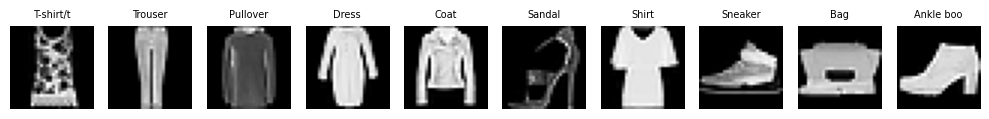

In [ ]:
import hashlib, json, re, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

torch.manual_seed(0)
np.random.seed(0)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

DATA = Path("data")
DATA.mkdir(exist_ok=True)

# корпус русской поэзии для задачи 3: Пушкин, Тютчев, Блок, Есенин, Маяковский (общественное достояние)
POETRY_URL = ("https://huggingface.co/datasets/AnyaSchen/russian_poetry_with_keywords/"
              "resolve/573301ba20219a35166586b9619c04e891ddd801/data/train-00000-of-00001-a239d0191cfafaf5.parquet")
if not (DATA / "russian_poetry.parquet").exists():
    urllib.request.urlretrieve(POETRY_URL, DATA / "russian_poetry.parquet")

POETRY_SHA256 = "79cd5db9beb2f9d544a232f51fbc110557edd07995ae97c1fa9376b96878bb89"
assert hashlib.sha256((DATA / "russian_poetry.parquet").read_bytes()).hexdigest() == POETRY_SHA256, "Корпус изменился: нужен файл закреплённой версии"

# FashionMNIST: 10 классов одежды, картинки 28×28 в оттенках серого
fm_train = torchvision.datasets.FashionMNIST(DATA, train=True, download=True)
fm_test = torchvision.datasets.FashionMNIST(DATA, train=False, download=True)
CLASSES = fm_train.classes


def stratified(y, per_class, seed=0):
    rng = np.random.RandomState(seed)
    idx = np.concatenate([rng.choice(np.where(y == c)[0], per_class, replace=False) for c in range(10)])
    return rng.permutation(idx)


ytr_all, y_eval_all = fm_train.targets.numpy(), fm_test.targets.numpy()
itr, ival = stratified(ytr_all, 100), stratified(y_eval_all, 200, seed=1)
Xtr, ytr = fm_train.data.numpy()[itr], ytr_all[itr]      # 1000 картинок на обучение
Xval, yval = fm_test.data.numpy()[ival], y_eval_all[ival]   # 2000 на validation, подбор здесь
print("train:", Xtr.shape, " validation:", Xval.shape)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, c in zip(axes, range(10)):
    ax.imshow(Xtr[ytr == c][0], cmap="gray")
    ax.set_title(CLASSES[c][:9], fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Общие функции

| Интерфейс | Назначение |
|---|---|
| `make_model(pretrained=True)` | Свежая ResNet-18 с новой головой, фиксированная инициализация |
| `extract(model, X, size=64, train_mode=False)` | Словарь `{этап: {gap/gmp: массив (N,C)}}` |
| `probe(Ftr, Fval, ...)` | StandardScaler + логистическая регрессия, метрика на validation |
| `accuracy(model, X, y, size=64)` | Accuracy классификационной головы |
| `check(name, value, threshold)` | Проверка учебного ориентира |

`probe` по умолчанию использует глобальные `ytr`, `yval`. `extract` задаёт режим модели через `train_mode`. В задачах учитывайте эти детали интерфейса, а не только формы возвращаемых массивов.

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def preprocess(x_uint8, size=64):
    '''(B, 28, 28) uint8 -> (B, 3, size, size): серую картинку повторяем в три канала и нормируем как ImageNet.'''
    x = torch.from_numpy(np.ascontiguousarray(x_uint8)).unsqueeze(1).float() / 255
    x = x.repeat(1, 3, 1, 1)
    x = v2.functional.resize(x, [size, size], antialias=True)
    return ((x - MEAN) / STD).contiguous()


def make_model(pretrained=True, n_classes=10):
    '''ResNet-18 с новой головой на 10 классов. Голова всегда инициализируется одинаково.'''
    torch.manual_seed(0)
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(512, n_classes)
    return m.to(device)


LEVELS = ["stem", "layer1", "layer2", "layer3", "layer4"]


def blocks_of(m):
    return {"stem": nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool),
            "layer1": m.layer1, "layer2": m.layer2, "layer3": m.layer3, "layer4": m.layer4}


@torch.no_grad()
def extract(model, X, size=64, bs=250, train_mode=False):
    '''Признаки со всех этажей за один проход.

    Возвращает {этаж: {"gap": (N, C), "gmp": (N, C)}} — среднее и максимум по пространству.
    '''
    model = model.to(device)
    model.train(train_mode)
    blocks = blocks_of(model)
    feats = {k: {"gap": [], "gmp": []} for k in LEVELS}
    for i in range(0, len(X), bs):
        h = preprocess(X[i:i + bs], size).to(device)
        for name, block in blocks.items():
            h = block(h)
            feats[name]["gap"].append(h.mean(dim=(2, 3)).cpu())
            feats[name]["gmp"].append(h.amax(dim=(2, 3)).cpu())
    return {k: {p: torch.cat(v).numpy() for p, v in d.items()} for k, d in feats.items()}


def probe(Ftr, Fval, ytrain=None, yvalid=None, C=0.01):
    '''Линейный зонд: логистическая регрессия на замороженных признаках -> accuracy на validation.'''
    ytrain = ytr if ytrain is None else ytrain
    yvalid = yval if yvalid is None else yvalid
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    clf.fit(Ftr, ytrain)
    return float(clf.score(Fval, yvalid))


@torch.no_grad()
def accuracy(model, X, y, size=64, bs=250):
    model.eval()
    pred = torch.cat([model(preprocess(X[i:i + bs], size).to(device)).argmax(1).cpu() for i in range(0, len(X), bs)])
    return float((pred.numpy() == y).mean())


results = {}          # сюда складываем числа семинара, в конце соберём таблицу


def check(name, value, threshold, higher_is_better=True):
    '''Проверка ответа: печатает ваше число и порог.'''
    if value is None:
        print(f"[ ?  ] {name}: ответа пока нет")
        return
    ok = value >= threshold if higher_is_better else value <= threshold
    sign = "≥" if higher_is_better else "≤"
    print(f"[{'OK ' if ok else 'нет'}] {name}: {value:.4f}, нужно {sign} {threshold}")
    results[name] = round(float(value), 4)


t0 = time.time()
_ = extract(make_model(), Xtr[:250], size=64)
print(f"пробный прогон 250 картинок: {time.time() - t0:.1f} с — окружение готово")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 105MB/s]


пробный прогон 250 картинок: 4.6 с — окружение готово


### Подготовка поэтической задачи

Следующая ячейка готовит списки `L` и `R` и функцию оценки для задачи 3. Берём первые восемь непустых строк каждого произведения и делим каждую строку между словами у ближайшего к середине пробела. `L` содержит столбцы начал строк, `R` — перемешанные столбцы окончаний. Это готовая инфраструктура: на занятии пишем функцию совместимости и не меняем генератор или правильные пары.

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.feature_extraction.text import TfidfVectorizer

N_PAIRS, FRAGMENT_LINES = 200, 8
leaderboard = []


def poem_key(text):
    return re.sub(r"\W+", "", text.lower())


def fragment_lines(text):
    # Пробелы внутри строки нормализуем, пустые строки между строфами убираем.
    lines = [" ".join(line.split()) for line in text.splitlines() if line.strip()]
    return lines[:FRAGMENT_LINES]


def select_poetry(rows, n=200):
    # Отбираем целые произведения до разреза. Одинаковые восьмистрочия тоже исключаем.
    pool, seen_poems, seen_fragments = [], set(), set()
    for r in rows:
        lines = fragment_lines(r["text"])
        if len(lines) != FRAGMENT_LINES or any(" " not in line for line in lines):
            continue
        key, fragment_key = poem_key(r["text"]), poem_key("\n".join(lines))
        if key in seen_poems or fragment_key in seen_fragments:
            continue
        pool.append(r)
        seen_poems.add(key)
        seen_fragments.add(fragment_key)
    chosen = np.random.RandomState(0).choice(len(pool), n, replace=False)
    validation = [pool[i] for i in chosen]
    return validation


def make_matching_problem(records, seed):
    halves = []
    for r in records:
        lines = fragment_lines(r["text"])
        if len(lines) != FRAGMENT_LINES or any(" " not in line for line in lines):
            raise ValueError("Нужен фрагмент с заданным числом строк, минимум два слова в каждой")
        left_lines, right_lines = [], []
        for line in lines:
            # Ближайший к середине пробел; при равенстве расстояний берём левый.
            spaces = [i for i, ch in enumerate(line) if ch == " "]
            cut = min(spaces, key=lambda i: abs(2 * i - len(line)))
            left_lines.append(line[:cut])
            right_lines.append(line[cut + 1:])
        halves.append(("\n".join(left_lines), "\n".join(right_lines)))
    left, ordered_right = map(list, zip(*halves))
    permutation = np.random.RandomState(seed).permutation(len(records))
    right = [ordered_right[i] for i in permutation]
    return left, right, np.argsort(permutation)


def evaluate_matching(S, expected):
    S = np.asarray(S, dtype=np.float64)
    n = len(expected)
    if S.shape != (n, n) or not np.isfinite(S).all():
        raise ValueError(f"Нужна конечная матрица {(n, n)}")
    _, prediction = linear_sum_assignment(-S)
    return {"доля пар": float((prediction == expected).mean()),
            "argmax": float((S.argmax(1) == expected).mean())}


def score(S, name="без названия", record=True):
    metric = evaluate_matching(S, truth)  # truth используется только проверкой
    acc, am = metric["доля пар"], metric["argmax"]
    correct = int(round(acc * len(truth)))
    errors = len(truth) - correct
    print(f"{name:30s} {correct}/{len(truth)} пар | accuracy {acc:.3f} | "
          f"ошибок {errors} | argmax {am:.3f}")
    if record:
        leaderboard.append({"решение": name, "верных пар": correct, "ошибок": errors,
                            "доля пар": acc, "argmax": am})
    return metric


def z(S):
    # Эвристика для согласования масштаба двух сигналов, не гарантия улучшения.
    S = np.asarray(S, dtype=np.float64)
    return (S - S.mean()) / (S.std() + 1e-9)


def leaderboard_table():
    table = pd.DataFrame(leaderboard, columns=["решение", "верных пар", "ошибок", "доля пар", "argmax"])
    return table.sort_values("доля пар", ascending=False, kind="stable").reset_index(drop=True)


records = select_poetry(pd.read_parquet(DATA / "russian_poetry.parquet").to_dict("records"), N_PAIRS)
L, R, truth = make_matching_problem(records, seed=1)
del records  # исходные произведения не участвуют в решении
print("пар в задаче:", len(L))
for name, texts in [("левые", L), ("правые", R)]:
    lengths = [t.count("\n") + 1 for t in texts]
    print(name, "строк min / median / max:", min(lengths), np.median(lengths), max(lengths))
print("\nПример левой части:\n" + L[0])

пар в задаче: 200
левые строк min / median / max: 8 8.0 8
правые строк min / median / max: 8 8.0 8

Пример левой части:
Давно на почве
Где ложь так
Давно наукой
Двойная правда
Для них — закон и
Для нас —
И закрепила
Их как наследие


### Готовая языковая модель для задачи 3

Используем [ruGPT-3 Small](https://huggingface.co/ai-forever/rugpt3small_based_on_gpt2): модель предсказывает следующий токен по предыдущим. Загружаем её до занятия. Веса заморожены, новые тексты не генерируем.

`continuation_logprobs(prefixes, endings)` принимает равные по длине списки начал и окончаний строк. Возвращает для каждой пары сумму логарифмов вероятностей токенов окончания при условии начала. Чем выше число, тем естественнее для модели такое продолжение. Вероятности токенов самого начала в оценку не входят. Функция считает только переданные пары; матрицу для всех кандидатов участник строит в задаче 3.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

POETRY_MODEL = "ai-forever/rugpt3small_based_on_gpt2"
POETRY_REV = "a9307e696cd3c5b7f953ff4cb19d76a4d81821d5"
poetry_tokenizer = AutoTokenizer.from_pretrained(POETRY_MODEL, revision=POETRY_REV)
poetry_tokenizer.pad_token = poetry_tokenizer.eos_token
poetry_lm = AutoModelForCausalLM.from_pretrained(POETRY_MODEL, revision=POETRY_REV,
                                               attn_implementation="sdpa").to(device).eval()
poetry_lm.requires_grad_(False)
poetry_lm.config.use_cache = False


@torch.inference_mode()
def continuation_logprobs(prefixes, endings, bs=128, token_limit=None):
    if len(prefixes) != len(endings):
        raise ValueError("Нужны равные по длине списки начал и окончаний")
    if not prefixes:
        return np.empty(0)
    # Повторяющиеся строки токенизируем один раз. Пробел принадлежит окончанию.
    unique_left, unique_right = list(dict.fromkeys(prefixes)), list(dict.fromkeys(endings))
    a = dict(zip(unique_left, poetry_tokenizer(unique_left, add_special_tokens=False)["input_ids"]))
    b = dict(zip(unique_right, poetry_tokenizer([" " + t for t in unique_right],
                                               add_special_tokens=False)["input_ids"]))
    # Одинаковые запросы, особенно для первого токена, считаем один раз.
    requests = [(tuple(a[l]), tuple(b[r][:token_limit])) for l, r in zip(prefixes, endings)]
    pair_index = {pair: i for i, pair in enumerate(dict.fromkeys(requests))}
    inverse = [pair_index[pair] for pair in requests]
    pairs = list(pair_index)
    if any(not l or not r for l, r in pairs):
        raise ValueError("Начало и окончание должны содержать токены")
    order = sorted(range(len(pairs)), key=lambda i: len(pairs[i][0]) + len(pairs[i][1]))
    values = np.empty(len(pairs), dtype=np.float64)
    for start in range(0, len(order), bs):
        indices = order[start:start + bs]
        batch = [pairs[i] for i in indices]
        width = max(len(l) + len(r) for l, r in batch)
        ids = torch.full((len(batch), width), poetry_tokenizer.pad_token_id, dtype=torch.long)
        mask = torch.zeros_like(ids)
        rows, positions, targets, lengths = [], [], [], []
        for row, (l, r) in enumerate(batch):
            ids[row, :len(l) + len(r)] = torch.tensor(l + r)
            mask[row, :len(l) + len(r)] = 1
            # Токен в позиции t предсказывается по скрытому состоянию t-1.
            rows.extend([row] * len(r))
            positions.extend(range(len(l) - 1, len(l) + len(r) - 1))
            targets.extend(r)
            lengths.append(len(r))
        hidden = poetry_lm.transformer(input_ids=ids.to(device),
                                       attention_mask=mask.to(device)).last_hidden_state
        selected = hidden[torch.tensor(rows, device=device), torch.tensor(positions, device=device)]
        logits = poetry_lm.lm_head(selected).float()
        logp = -F.cross_entropy(logits, torch.tensor(targets, device=device), reduction="none")
        offsets = np.r_[0, np.cumsum(lengths)[:-1]]
        values[indices] = np.add.reduceat(logp.cpu().numpy(), offsets)
    return values[inverse]


print("ruGPT-3 Small:", sum(p.numel() for p in poetry_lm.parameters()), "параметров")
print("Пробная оценка:", continuation_logprobs(["Белый снег"], ["тихо падал"]).round(3))

ruGPT-3 Small: 125231616 параметров
Пробная оценка: [-10.005]


## Задача 1. Код работает, но обучается не то

**12 минут на самостоятельную работу, затем 6 минут общего разбора.**

Вам достались три эксперимента с ResNet-18. Все запускаются без исключений, но каждый нарушает задуманный режим работы модели. В каждом фрагменте спрятана одна ошибка. Найдите её и исправьте, сохранив данные, learning rate и число эпох.

У A должны быть фиксированные признаки, у B должна обучаться только новая голова, у C — голова и последний блок тела. Фрагменты независимы: можно начать с любого, а B строит собственный кэш и не зависит от результата A.

Решение — исправленный код и наблюдение, которое подтверждает исправление. Например, нужные веса начали изменяться или признаки перестали зависеть от соседей по батчу. Просто получить более высокую accuracy недостаточно: она не показывает, почему эксперимент изменился.

На разборе откроем несколько ваших исправлений в Colloq и проверим их запуском.

### A. Сеть как фиксированный преобразователь

Хотим один раз получить признаки картинок готовой ResNet-18 и обучить на них логистическую регрессию. Веса ResNet меняться не должны, а признаки одной картинки должны зависеть от неё самой, а не от состава батча.

В коде уже выставлено `requires_grad=False`. Достаточно ли этого для задуманного режима? Исправьте фрагмент и проверьте, что действительно изменилось.

In [ ]:
# ФРАГМЕНТ A (сломан)
model = make_model()
for p in model.parameters():
    p.requires_grad = False                      # веса не обучаются

Ftr_a = extract(model, Xtr, size=64, train_mode=False)
Fval_a = extract(model, Xval, size=64, train_mode=False)

acc_a = probe(Ftr_a["layer4"]["gap"], Fval_a["layer4"]["gap"])
print("зонд на layer4:", round(acc_a, 4))
check("1A: зонд на замороженных признаках", acc_a, 0.80)

зонд на layer4: 0.8325
[OK ] 1A: зонд на замороженных признаках: 0.8325, нужно ≥ 0.8


### B. Обучаем голову на готовых признаках

Здесь кэш уже корректный: матрицы признаков не меняются во время обучения. Нужно обучить линейную голову пять эпох, делая обычный шаг AdamW после каждого батча. Накопление градиентов между шагами не задумано.

Найдите расхождение между этим описанием и циклом ниже. Исправьте его и сравните ход обучения на тех же батчах.

In [ ]:
# ФРАГМЕНТ B (сломан)
# Собственный корректный кэш: B можно исправлять раньше A.
model_b = make_model().eval()
Fb_tr = extract(model_b, Xtr, size=64)["layer4"]["gap"]
Fb_val = extract(model_b, Xval, size=64)["layer4"]["gap"]
Ftr_t = torch.as_tensor(Fb_tr).to(device)
Fval_t = torch.as_tensor(Fb_val).to(device)
ytr_t = torch.as_tensor(ytr).to(device)

torch.manual_seed(0)
head = nn.Linear(512, 10).to(device)
opt = torch.optim.AdamW(head.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(0)

for ep in range(5):
    for j in torch.randperm(len(Ftr_t), generator=gen).split(64):
        opt.zero_grad()
        j = j.to(device)
        loss = F.cross_entropy(head(Ftr_t[j]), ytr_t[j])
        loss.backward()
        opt.step()
    with torch.no_grad():
        acc_b = float((head(Fval_t).argmax(1).cpu().numpy() == yval).mean())
    print(f"эпоха {ep + 1}: validation accuracy {acc_b:.4f}")

check("1B: голова на кэше признаков", acc_b, 0.75)

эпоха 1: validation accuracy 0.5795
эпоха 2: validation accuracy 0.7570
эпоха 3: validation accuracy 0.7815
эпоха 4: validation accuracy 0.7915
эпоха 5: validation accuracy 0.7975
[OK ] 1B: голова на кэше признаков: 0.7975, нужно ≥ 0.75


### C. Размораживаем последний блок

Теперь хотим дообучать `layer4` с `lr=1e-4` и голову `fc` с `lr=1e-3`. Остальные веса должны остаться прежними. В коде есть проверка сдвига одного из весов `layer4`.

Добейтесь, чтобы заявленный режим действительно выполнялся: нужные параметры получают градиенты и обновляются, а замороженная часть не сдвигается. Подтвердите это измерением.

In [ ]:
# ФРАГМЕНТ C (сломан)
torch.manual_seed(0)
model_c = make_model()
for p in model_c.parameters():
    p.requires_grad = False
for p in model_c.layer4.parameters():
    p.requires_grad = True
for p in model_c.fc.parameters():
    p.requires_grad = True

opt = torch.optim.AdamW([
    {"params": model_c.fc.parameters(), "lr": 1e-3},
    {"params": model_c.layer4.parameters(), "lr": 1e-4},
])


stem_before = model_c.conv1.weight.detach().clone()
w0 = model_c.layer4[1].conv2.weight.detach().clone()
gen = torch.Generator().manual_seed(0)
for ep in range(3):
    model_c.train()
    for m in model_c.modules():                              # BatchNorm замороженных блоков держим в eval
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()
    for j in torch.randperm(len(Xtr), generator=gen).split(64):
        j = j.numpy()
        loss = F.cross_entropy(model_c(preprocess(Xtr[j]).to(device)), torch.as_tensor(ytr[j]).to(device))
        loss.backward()
        opt.step()
        opt.zero_grad()
    acc_c = accuracy(model_c, Xval, yval)
    print(f"эпоха {ep + 1}: validation accuracy {acc_c:.4f}")

shift = float((model_c.layer4[1].conv2.weight.detach() - w0).abs().max())
print("максимальный сдвиг весов в layer4:", round(shift, 6))
check("1C: layer4 + голова", acc_c, 0.80)
optimizer_ids = {id(p) for group in opt.param_groups for p in group["params"]}
expected_ids = {id(p) for p in model_c.parameters() if p.requires_grad}
stem_shift = float((model_c.conv1.weight.detach() - stem_before).abs().max())
mechanism_ok = optimizer_ids == expected_ids and shift > 0 and stem_shift == 0
print("параметры оптимизатора совпадают с обучаемыми:", optimizer_ids == expected_ids)
print("сдвиг замороженного conv1:", stem_shift)
print("[OK] механика C" if mechanism_ok else "[нет] проверьте param_groups и сдвиги весов")

эпоха 1: validation accuracy 0.7810
эпоха 2: validation accuracy 0.8285
эпоха 3: validation accuracy 0.8365
максимальный сдвиг весов в layer4: 0.003459
[OK ] 1C: layer4 + голова: 0.8365, нужно ≥ 0.8
параметры оптимизатора совпадают с обучаемыми: True
сдвиг замороженного conv1: 0.0
[OK] механика C


### Смотрим исправления участников

Откроем в Colloq по одному исправлению для A, B и C. Автор показывает изменённую строку и результат проверки; затем запускаем код и обсуждаем, соответствует ли поведение исходному условию. Если два исправления разные, проверяем оба при одинаковых настройках.

## Задача 2. Где брать признаки одежды?

**18 минут на решение, затем 7 минут разбора.**

Есть готовая ResNet-18, обученная на фотографиях ImageNet. Теперь ей предстоит работать с маленькими чёрно-белыми изображениями одежды FashionMNIST. Можно взять признаки с конца сети, а можно остановиться раньше. Кроме того, картинку можно подать в разном масштабе, а карту признаков свернуть средним или максимумом.

У вас **1000 обучающих изображений** и **2000 для validation**. Веса ResNet не меняем. На выбранных признаках обучаем только линейный классификатор — это делает готовая функция `probe`. Исходный вариант уже задан: `layer4`, средний пулинг (`gap`), размер входа 224.

Найдите конфигурацию с validation accuracy **не ниже 0,845**. Сравните её с двумя альтернативами: логистической регрессией на сырых пикселях и той же ResNet со случайными весами. У случайной сети используйте выбранные вами размер, слой и пулинг: иначе одновременно изменятся и веса, и способ извлечения признаков.

### Что разрешено выбирать

<img src="attachment:4cc854bae52a5e37d183147b288ae051.png" width="1000">

На рисунке показаны размеры для входа 128×128. Выбираем три настройки:

| Настройка | Варианты |
|---|---|
| Размер входа | 32, 64, 128, 224 |
| Этап извлечения | stem, layer1, layer2, layer3, layer4 |
| Пулинг по каждому каналу | среднее `gap` или максимум `gmp` |

Всего 40 комбинаций. При одном размере входа `extract` сразу возвращает признаки всех пяти этапов с обоими пулингами, поэтому отдельный forward для каждой комбинации не нужен.

В Colloq покажите код перебора, таблицу результатов и выбранную тройку `best_config`. Рядом должны быть два контрольных результата и время извлечения. На разборе сравним, за какое улучшение качества пришлось заплатить вычислениями.

In [ ]:
# Бейзлайн: как сделал бы человек по памяти после лекции
model = make_model()
for p in model.parameters():
    p.requires_grad = False

Ftr_224 = extract(model, Xtr, size=224)
Fval_224 = extract(model, Xval, size=224)
baseline = probe(Ftr_224["layer4"]["gap"], Fval_224["layer4"]["gap"])
print("бейзлайн (layer4, gap, 224):", round(baseline, 4))
results["2: бейзлайн layer4@224"] = round(baseline, 4)

бейзлайн (layer4, gap, 224): 0.8385


### Строим таблицу вариантов

Запустите исходную конфигурацию, затем допишите перебор. Один вызов `extract` при заданном размере входа даёт весь набор признаков; дальше остаётся выбрать слой и пулинг и передать массивы в `probe`. Сохраните лучшую тройку в `best_config`.

In [ ]:
# ВАШ КОД. Заготовка ниже снимает признаки один раз на каждое разрешение —
# извлечение самое дорогое, внутри цикла его быть не должно.
grid = {}
for size in (32, 64, 128, 224):
    t0 = time.time()
    if size == 224:
        Ftr_s, Fval_s = Ftr_224, Fval_224
    else:
        Ftr_s = extract(model, Xtr, size=size)
        Fval_s = extract(model, Xval, size=size)
    for level in LEVELS:
        for pooling in ("gap", "gmp"):
            grid[(size, level, pooling)] = probe(Ftr_s[level][pooling], Fval_s[level][pooling])          # <-- посчитайте зонд и положите его в grid[(size, level, pooling)]
    print(f"размер {size:3d}: {time.time() - t0:5.1f} с" + (" (кэш: без извлечения)" if size == 224 else " (включая извлечение)"))

best_config = max(grid, key=grid.get) if grid else None
best_acc = grid[best_config] if grid else None

print("лучшее:", best_config, best_acc)
check("2A: лучшая конфигурация", best_acc, 0.845)

размер  32:   6.1 с (включая извлечение)
размер  64:   8.8 с (включая извлечение)
размер 128:  12.7 с (включая извлечение)
размер 224:   7.5 с (кэш: без извлечения)
лучшее: (128, 'layer3', 'gap') 0.8535
[OK ] 2A: лучшая конфигурация: 0.8535, нужно ≥ 0.845


### С чем сравнить найденный вариант

Для сырых пикселей одна картинка — вектор из 784 чисел. Для случайной ResNet извлеките признаки с теми же размером, слоем и пулингом, что в `best_config`. Обе оценки считаем тем же `probe` на тех же данных.

Первое сравнение показывает выигрыш всего способа извлечения признаков относительно пикселей. Второе помогает выделить пользу предобученных весов при фиксированной архитектуре и конфигурации.

In [ ]:
Xtr.reshape(1000, 28, 28)

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [ ]:
# ВАШ КОД: два контроля.
# 1) логистическая регрессия на сырых пикселях: картинку 28×28 разверните в вектор из 784 чисел и поделите на 255;
# 2) resnet18(weights=None), та же best_config: разрешение, этаж, пулинг; та же регуляризация C.
Xtr_r, Xval_r = Xtr.reshape(1000, 784), Xval.reshape(2000, 784)
torch.manual_seed(0)
rand_model = resnet18(weights=None)
Xtr_rand = extract(rand_model, Xtr, size=128)['layer3']['gap']
Xval_rand = extract(rand_model, Xval, size=128)['layer3']['gap']
acc_pixels = probe(Xtr_r, Xval_r)
acc_random = probe(Xtr_rand, Xval_rand)

print("сырые пиксели:            ", acc_pixels)
print("случайные веса:           ", acc_random)
check("2B: зонд на сырых пикселях", acc_pixels, 0.70)
check("2B: зонд на случайных весах", acc_random, 0.70)

сырые пиксели:             0.798
случайные веса:            0.7535
[OK ] 2B: зонд на сырых пикселях: 0.7980, нужно ≥ 0.7
[OK ] 2B: зонд на случайных весах: 0.7535, нужно ≥ 0.7


### Обсуждаем решения в Colloq

Посмотрим две таблицы участников: с высоким качеством и с интересным компромиссом по времени. Запустим выбранные конфигурации и их контроли. Обсудим, совпал ли лучший слой, помог ли большой вход и какое сравнение позволяет говорить именно о пользе предобучения.

Если варианты отличаются на три картинки из 2000, это ещё не доказательство устойчивого превосходства. Для обсуждения такой разницы нужны дополнительные наблюдения.

## Задача 3. Стихи разрезали вертикально

**30 минут на решение, затем 12 минут разбора.**

Из каждого из 200 стихотворений взяли первые **8 непустых строк**. Каждую строку разделили **между словами**, у ближайшего к середине пробела. Получились два столбца: начала всех восьми строк и их окончания. Правые столбцы перемешали целиком; порядок строк внутри столбца сохранили.

Подберите к каждому левому столбцу правый, использовав каждый правый ровно один раз. Слова целые; при соединении частей вставляем один пробел.

Учебный пример разреза (показаны две строки):

| Левый столбец | Правый столбец |
|---|---|
| Белый снег | тихо падал |
| Над рекой | горели звёзды |

В лекции искали продолжение после первых строк стихотворения. Здесь соединяем части **каждой строки**. Во всех столбцах по восемь строк; их количество не подсказывает ответ.

### Что написать

`build_similarity(left, right)` получает два списка по N текстов и возвращает **матрицу N×N** оценок совместимости. Больше — лучше. Готовая проверка выбирает взаимно однозначные пары с максимальной суммой оценок. Алгоритм назначения реализовывать не требуется.

Цель — восстановить **не меньше 98% пар**, то есть хотя бы 196 из 200. Стартовый нейросетевой метод ниже уже восстанавливает 91%. Попробуйте использовать больше информации о соединяемых строках. Метрика — доля правильно восстановленных пар; сравниваем также число ошибок.

Разрешены выданные тексты, готовая языковая модель и документация. Правильные соответствия используются только функцией оценки. Исходные целые стихотворения, перестановку генератора и поиск произведений в интернете не используем.

В Colloq покажите функцию, результат и время работы. Объясните, какие токены участвуют в оценке и как оценки восьми строк превращаются в оценку пары столбцов.

### Сильный старт: вероятность первого токена справа

Уже загруженная ruGPT-3 Small оценивает, насколько естественно продолжить начало строки предложенным окончанием. Начнём с вероятности **первого токена** окончания. Токен не обязательно совпадает со словом: токенизатор может разбивать слово на несколько частей, хотя в самой задаче слова остаются целыми.

Для каждой пары столбцов оцениваем восемь соединений «строка k слева → строка k справа», затем складываем логарифмы вероятностей. Деление суммы на восемь не меняет назначение: число строк одинаково у всех.

Для первого токена достаточно одного forward на каждое начало строки: модель выдаёт распределение по всему словарю. Из него берём вероятности первых токенов всех правых кандидатов. Для более длинных окончаний используйте `continuation_logprobs` из подготовки.

In [ ]:
L[:4]

['Давно на почве\nГде ложь так\nДавно наукой\nДвойная правда\nДля них — закон и\nДля нас —\nИ закрепила\nИх как наследие',
 'Просочится солнце\nкак маленькая\nи спрячется на\nгде громоздится\nСердце девушки,\nОкаменелый обломок\nИ еще на булавке\nзасушенного хвоста',
 'Куда они?И\nСтепная водь не\nНе знаю, светит\nИль всадник\nВсе\nНо понял\nСтрану родную в\nОгнем и саблями',
 'Я знаю\nИ\nГлаза печальнее\nСредь человечьих\nКак пруд, заплесневела\nКто бросит камень\nНе\nБудет запах']

In [ ]:
@torch.inference_mode()
def first_token_similarity(left, right, bs=64):
    left_lines = [line for text in left for line in text.split("\n")]
    right_lines = [line for text in right for line in text.split("\n")]
    tokenized = poetry_tokenizer([" " + line for line in right_lines], add_special_tokens=False)
    first_ids = np.array([ids[0] for ids in tokenized["input_ids"]]).reshape(len(right), 8)
    S = np.zeros((len(left), len(right)))
    # Один forward на начало строки даёт вероятности сразу всех следующих токенов.
    for start in range(0, len(left_lines), bs):
        batch = poetry_tokenizer(left_lines[start:start + bs], padding=True, padding_side="right",
                                 add_special_tokens=False, return_tensors="pt").to(device)
        hidden = poetry_lm.transformer(**batch).last_hidden_state
        last = batch["attention_mask"].sum(1) - 1  # padding справа
        vectors = hidden[torch.arange(len(last), device=device), last]
        logp = poetry_lm.lm_head(vectors).float().log_softmax(-1)
        indices = np.arange(start, start + len(last))
        targets = torch.tensor(first_ids[:, indices % 8].T.copy(), device=device)
        values = logp.gather(1, targets).cpu().numpy() / 8
        np.add.at(S, indices // 8, values)
    return S

t0 = time.time()
S_start = first_token_similarity(L, R)
score(S_start, "ruGPT: первый токен")
print(f"Время стартового метода: {time.time() - t0:.1f} с")

1600
ruGPT: первый токен            182/200 пар | accuracy 0.910 | ошибок 18 | argmax 0.350
Время стартового метода: 1.0 с


### Теперь ваша очередь

Допишите `build_similarity(left, right)`. Первый токен иногда мало говорит о продолжении: у разных слов он может совпасть. Проверьте, как меняется результат при оценке более длинной части окончания. `token_limit=None` в готовой функции означает все токены.

Сравните сумму и среднее логарифмов вероятностей, придумайте способ объединить восемь строк. Можно добавить признаки слоговой длины или другие сигналы. Измеряйте вклад изменения отдельно: сложная смесь не обязана быть лучше одного сильного метода.

Покажите результат независимых максимумов и назначения. Если они сильно различаются, объясните, какой вариант выполняет условие задачи. Сохраните удачную функцию для общего разбора.

In [ ]:
@torch.inference_mode()
def continuation_logprobs(prefixes, endings, bs=128, token_limit=None):
    if len(prefixes) != len(endings):
        raise ValueError("Нужны равные по длине списки начал и окончаний")
    if not prefixes:
        return np.empty(0)
    # Повторяющиеся строки токенизируем один раз. Пробел принадлежит окончанию.
    unique_left, unique_right = list(dict.fromkeys(prefixes)), list(dict.fromkeys(endings))
    a = dict(zip(unique_left, poetry_tokenizer(unique_left, add_special_tokens=False)["input_ids"]))
    b = dict(zip(unique_right, poetry_tokenizer([" " + t for t in unique_right],
                                               add_special_tokens=False)["input_ids"]))
    # Одинаковые запросы, особенно для первого токена, считаем один раз.
    requests = [(tuple(a[l]), tuple(b[r][:token_limit])) for l, r in zip(prefixes, endings)]
    pair_index = {pair: i for i, pair in enumerate(dict.fromkeys(requests))}
    inverse = [pair_index[pair] for pair in requests]
    pairs = list(pair_index)
    if any(not l or not r for l, r in pairs):
        raise ValueError("Начало и окончание должны содержать токены")
    order = sorted(range(len(pairs)), key=lambda i: len(pairs[i][0]) + len(pairs[i][1]))
    values = np.empty(len(pairs), dtype=np.float64)
    for start in range(0, len(order), bs):
        indices = order[start:start + bs]
        batch = [pairs[i] for i in indices]
        width = max(len(l) + len(r) for l, r in batch)
        ids = torch.full((len(batch), width), poetry_tokenizer.pad_token_id, dtype=torch.long)
        mask = torch.zeros_like(ids)
        rows, positions, targets, lengths = [], [], [], []
        for row, (l, r) in enumerate(batch):
            ids[row, :len(l) + len(r)] = torch.tensor(l + r)
            mask[row, :len(l) + len(r)] = 1
            # Токен в позиции t предсказывается по скрытому состоянию t-1.
            rows.extend([row] * len(r))
            positions.extend(range(len(l) - 1, len(l) + len(r) - 1))
            targets.extend(r)
            lengths.append(len(r))
        hidden = poetry_lm.transformer(input_ids=ids.to(device),
                                       attention_mask=mask.to(device)).last_hidden_state
        selected = hidden[torch.tensor(rows, device=device), torch.tensor(positions, device=device)]
        logits = poetry_lm.lm_head(selected).float()
        logp = -F.cross_entropy(logits, torch.tensor(targets, device=device), reduction="none")
        offsets = np.r_[0, np.cumsum(lengths)[:-1]]
        values[indices] = np.add.reduceat(logp.cpu().numpy(), offsets)
    return values[inverse]


print("ruGPT-3 Small:", sum(p.numel() for p in poetry_lm.parameters()), "параметров")
print("Пробная оценка:", continuation_logprobs(["Белый снег"], ["тихо падал"]).round(3))

In [ ]:
def build_similarity(left, right):
    left_lines = [poem.splitlines() for poem in left]
    right_lines = [poem.splitlines() for poem in right]

    if any(len(p) != 8 for p in left_lines + right_lines):
        raise ValueError("В каждом стихотворении должно быть 8 строк")

    S = np.zeros((len(left), len(right)))

    for j, r in enumerate(right_lines):
        for k in range(8):
            prefixes = [poem[k] for poem in left_lines]
            endings = [r[k]] * len(left)

            res = continuation_logprobs(prefixes, endings)
            S[:, j] += res / 8

    return S

t0 = time.time()
S_my = build_similarity(L, R)
score(S_my, "моё решение")
print(f"Время решения: {time.time() - t0:.1f} с")

моё решение                    200/200 пар | accuracy 1.000 | ошибок 0 | argmax 0.190
Время решения: 240.9 с


### Сравниваем ваши решения

Выведите таблицу запусков. Наставник выберет несколько решений из Colloq: вариант с высоким качеством, быстрый вариант и необычный признак. Сначала смотрим код и результат, затем обсуждаем причину выигрыша. Если ошибок не осталось, сравниваем время и объём вычислений.

In [ ]:
leaderboard_table()

## Задача 4. На что потратить 100 разметок?

**Резерв: 15–20 минут на решение и 5 минут разбора, если основной маршрут закончен раньше.**

Есть **3000 изображений одежды без меток**. Эксперт готов разметить только **100**. После этого на выбранных примерах обучат классификатор и измерят его accuracy на 2000 оценочных изображениях. Какие картинки выгоднее отдать эксперту?

Используем готовые признаки ResNet-18: `layer3`, средний пулинг, вход 128×128. Модель и классификатор фиксированы для всех решений. Меняется только выбор ста изображений. Пул не пересекается с 1000 обучающих картинок первых задач.

Метки выдаёт `query(indices)`: передаёте индексы изображений в пуле и получаете классы. Можно запросить все 100 сразу или несколькими порциями, учитывая предыдущие ответы. Повторный запрос той же картинки не тратит бюджет повторно; попытка получить больше 100 разных меток отклоняется.

### Что написать

Функция `select_for_labeling(features, query, budget, seed)` выбирает изображения и вызывает `query`. Возвращать модель не нужно: проверка сама обучает один и тот же классификатор **с нуля, только по полученным меткам**.

Стратегия использует переданные признаки, ответы `query` и свой генератор случайных чисел. Метки из `fm_train.targets`, `ytr`, `yval`, ранее обученные головы и сохранённые ответы других запусков в стратегии не используем. Счётчик — часть учебного протокола, а не защита Python-кода от обхода.

Сравните стратегию со случайным выбором на **пяти одинаковых seed: 0–4**. В каждом запуске новый независимый бюджет 100; метки между запусками не переносятся. Цель — улучшить среднюю accuracy хотя бы на **3 процентных пункта**. В опорном опыте случайный выбор дал 75,94%, представители кластеров — 80,0%.

Покажите в Colloq код, пять результатов и их среднее. Объясните, какую информацию вы использовали при выборе следующих картинок.

### Подготовка пула и проверка бюджета

Эту ячейку запускаем как готовую инфраструктуру. Признаки стандартизуются по всему доступному неразмеченному пулу — для этого метки не нужны. Оценочные изображения в выборе примеров не участвуют.

| Интерфейс | Назначение |
|---|---|
| `features` внутри стратегии | Массив 3000×256, одинаковый для всех методов |
| `query(indices)` | Метки запрошенных изображений; не более 100 уникальных индексов |
| `fit_budget_classifier(X, y)` | Фиксированная логистическая регрессия; можно использовать внутри активной стратегии |
| `budget_run(strategy, seed)` | Один запуск выбора и оценка классификатора |
| `compare_queries(strategies)` | Таблицы средних и отдельных результатов по seed 0–4 |

In [ ]:
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier


class LabelBudget:
    def __init__(self, labels, budget=100):
        self._labels = np.asarray(labels).copy()
        self.budget = budget
        self._seen = set()
        if not 0 < budget <= len(self._labels):
            raise ValueError("Бюджет должен быть положительным и не больше размера пула")

    @property
    def used(self):
        return len(self._seen)

    @property
    def indices(self):
        return np.array(sorted(self._seen), dtype=int)

    def query(self, indices):
        ids = np.asarray(indices)
        if ids.ndim != 1:
            raise ValueError("Нужен одномерный список индексов")
        if ids.size == 0:
            return self._labels[:0].copy()
        if ids.dtype.kind not in "iu" or np.any(ids < 0) or np.any(ids >= len(self._labels)):
            raise ValueError("Индексы должны быть целыми и находиться внутри пула")
        new = set(ids.tolist()) - self._seen
        if self.used + len(new) > self.budget:
            raise ValueError(f"Бюджет {self.budget}: уже получено {self.used}, новых запрошено {len(new)}")
        self._seen.update(new)
        return self._labels[ids].copy()


def fit_budget_classifier(X, y):
    # Если пока известен только один класс, предсказываем его для всех примеров.
    model = (DummyClassifier(strategy="most_frequent") if len(np.unique(y)) == 1 else
             LogisticRegression(C=0.1, max_iter=2000))
    return model.fit(X, y)


def make_budget_runner(features, evaluation, pool_labels, evaluation_labels, budget=100):
    X, Xeval = np.asarray(features).copy(), np.asarray(evaluation).copy()
    labels, yeval = np.asarray(pool_labels).copy(), np.asarray(evaluation_labels).copy()

    def run(strategy, seed=0):
        oracle = LabelBudget(labels, budget)
        strategy(X.copy(), oracle.query, budget, seed)
        if oracle.used != budget:
            raise ValueError(f"Для сравнения нужно использовать ровно {budget} меток, получено {oracle.used}")
        ids = oracle.indices
        model = fit_budget_classifier(X[ids], oracle.query(ids))
        return {"seed": seed, "меток": oracle.used, "accuracy": float(model.score(Xeval, yeval))}

    return run


def compare_queries(strategies, seeds=range(5)):
    rows = []
    for name, strategy in strategies.items():
        for seed in seeds:
            t0 = time.time()
            outcome = budget_run(strategy, seed=seed)
            rows.append({"стратегия": name, **outcome, "секунд": time.time() - t0})
    trials = pd.DataFrame(rows)
    summary = trials.groupby("стратегия", sort=False).agg(
        accuracy=("accuracy", "mean"),
        разброс=("accuracy", lambda values: np.std(values, ddof=0)),
        меток=("меток", "max"),
        секунд=("секунд", "mean"))
    return summary.sort_values("accuracy", ascending=False), trials


available = np.setdiff1d(np.arange(len(fm_train)), itr)
pool_indices = np.random.default_rng(2026).choice(available, 3000, replace=False)
assert not np.intersect1d(pool_indices, itr).size
budget_model = make_model().eval().requires_grad_(False)
F_pool = extract(budget_model, fm_train.data.numpy()[pool_indices], size=128)["layer3"]["gap"]
F_eval = extract(budget_model, Xval, size=128)["layer3"]["gap"]
feature_scaler = StandardScaler().fit(F_pool)
F_pool = feature_scaler.transform(F_pool)
F_eval = feature_scaler.transform(F_eval)
budget_run = make_budget_runner(F_pool, F_eval, fm_train.targets.numpy()[pool_indices], yval)
print("пул:", F_pool.shape, "| оценка:", F_eval.shape, "| бюджет: 100 меток на запуск")

### Точка отсчёта: случайные 100 картинок

Стратегия ниже не смотрит на признаки. Измеряем её на пяти seed, чтобы сравнивать своё решение с распределением результатов, а не с одним удачным или неудачным выбором.

In [ ]:
def random_strategy(features, query, budget, seed):
    rng = np.random.default_rng(seed)
    query(rng.choice(len(features), budget, replace=False))


random_summary, random_trials = compare_queries({"случайно": random_strategy})
display(random_trials)
display(random_summary.round(4))

### Выберите полезные примеры

Два направления для поиска:

- **Разнообразие:** покрыть разные области пространства признаков, не потратив бюджет на много почти одинаковых картинок.
- **Неуверенность:** запросить небольшую порцию меток, обучить предварительный классификатор и выбирать следующие примеры там, где ему трудно принять решение.

Можно начать с любого направления или сочетать их. В активном варианте учитывайте, что к началу каждого нового запроса у вас есть только уже выданные метки.

In [ ]:
def select_for_labeling(features, query, budget, seed):
    # ВАШ КОД: выберите 100 изображений за один или несколько запросов.
    random_strategy(features, query, budget, seed)


# После изменения стратегии раскомментируйте сравнение:
# query_summary, query_trials = compare_queries({
#     "случайно": random_strategy, "моя стратегия": select_for_labeling})
# display(query_trials.pivot(index="seed", columns="стратегия", values="accuracy"))
# display(query_summary.round(4))